# ตรวจข้อมูล OASIS-1 ก่อนทำ Grad-CAM (รันทีเดียวทั้งไฟล์)

In [1]:
import os, sys, re, json, time, glob, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# ---------------- ตั้งค่า (แก้ให้ตรงกับเครื่อง) ----------------
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"   # โฟลเดอร์ที่มี split.json / processing_lock.py
DATA_ROOT = None            # None = ใช้ค่าจาก processing_lock (ตัวแปร OASIS_ROOT หรือค่าเริ่มต้นในไฟล์)
OUT_DIR = "A_check_output"
N_REG_SUBJECTS = 20         # จำนวนคนที่เอามาเฉลี่ยเป็นภาพอ้างอิงสำหรับจัดแนว atlas
N_CHECK_SUBJECTS = 12       # จำนวนคนที่ใช้นับว่าฮิปโปแคมปัสอยู่บนสไลซ์หรือไม่
TOLERANCE_MM = 5            # ความคลาดเคลื่อนที่ยอมรับได้จากการจัดแนว atlas (มิลลิเมตร)

# ถ้ามีไฟล์ atlas เอง (ต้องอยู่ในพื้นที่เดียวกับ template) ใส่พาธที่นี่ ไม่งั้นปล่อย None
ATLAS_PATH = None           # เช่น ".../HarvardOxford-sub-maxprob-thr25-1mm.nii.gz"
TEMPLATE_PATH = None        # เช่น ".../MNI152_T1_1mm_brain.nii.gz"
HIPPO_LABEL_VALUES = None   # None = หาจากชื่อ (Harvard-Oxford: ค่า 9 และ 19)


In [2]:
os.makedirs(OUT_DIR, exist_ok=True)
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import nibabel as nib

if DATA_ROOT is None:
    DATA_ROOT = PL.DATA_ROOT
print(PL.describe())
print("DATA_ROOT:", DATA_ROOT, "| มีอยู่:", os.path.isdir(DATA_ROOT))

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)
train_ids = [str(s).zfill(4) for s in split["train"]]
labels = split["labels"]
print("train:", len(train_ids), "คน")

REPORT = []          # เก็บข้อความสรุป เขียนลงไฟล์ตอนท้าย
def say(msg=""):
    print(msg); REPORT.append(str(msg))

say(f"วันที่รัน: {time.strftime('%Y-%m-%d %H:%M')} | nibabel {nib.__version__} | numpy {np.__version__}")
say(PL.describe())


processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)
DATA_ROOT: /home/jovyan/shared/donut/Alzheimer/OAS1 | มีอยู่: True
train: 163 คน
วันที่รัน: 2026-11-19 09:34 | nibabel 5.4.2 | numpy 2.4.6
processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)


## ส่วนที่ 1: OASIS-1 มีไฟล์ฮิปโปแคมปัสมาให้ไหม

In [3]:
sid0 = train_ids[0]
subj_dir = os.path.join(DATA_ROOT, f"OAS1_{sid0}_MR1")
say(f"คนตัวอย่าง: {sid0} | โฟลเดอร์: {subj_dir} | มีอยู่: {os.path.isdir(subj_dir)}")

files = []
for root, _, fs in os.walk(subj_dir):
    for fn in fs:
        files.append(os.path.relpath(os.path.join(root, fn), subj_dir))
files.sort()
say(f"จำนวนไฟล์ของคนนี้: {len(files)}")
hdr_files = [f for f in files if f.lower().endswith(".hdr")]
say(f"ไฟล์ .hdr ทั้งหมด {len(hdr_files)} ไฟล์ (หนึ่งไฟล์ .hdr = หนึ่งภาพ):")
for f in hdr_files[:60]:
    say("   " + f)
if len(hdr_files) > 60:
    say(f"   ... อีก {len(hdr_files) - 60} ไฟล์")

hits = [f for f in files if re.search(r"hippo|aseg|aparc|wmparc|freesurfer|label|parcel", f, re.I)]
say("\nไฟล์ที่ชื่อเกี่ยวกับฮิปโปแคมปัส/การแบ่งโครงสร้างสมอง: " + (", ".join(hits) if hits else "ไม่พบ"))

seg_files = [f for f in hdr_files if "seg" in f.lower()]
if not seg_files:
    say("ไม่พบไฟล์ที่ชื่อมี 'seg' (ภาพแบ่งเนื้อเยื่อ) ในโฟลเดอร์ของคนนี้")
for f in seg_files:
    arr = np.asarray(nib.load(os.path.join(subj_dir, f)).dataobj).squeeze()
    vals, cnt = np.unique(arr, return_counts=True)
    say(f"\n{f}: shape {arr.shape} | ค่าที่มีในภาพ {vals.tolist()} | จำนวนวอกเซลต่อค่า {cnt.tolist()}")
    if set(np.round(vals).astype(int).tolist()) <= {0, 1, 2, 3}:
        say("  -> มีแค่ค่า 0-3 = แบ่งเนื้อเยื่อ 3 ชนิด (น้ำไขสันหลัง/เนื้อเทา/เนื้อขาว) ไม่มีฮิปโปแคมปัสแยกมาให้")
    else:
        say("  -> มีค่ามากกว่า 3 ต้องดูความหมายของแต่ละค่าเพิ่ม (ส่งผลนี้มาให้ดู)")


คนตัวอย่าง: 0001 | โฟลเดอร์: /home/jovyan/shared/donut/Alzheimer/OAS1/OAS1_0001_MR1 | มีอยู่: True
จำนวนไฟล์ของคนนี้: 61
ไฟล์ .hdr ทั้งหมด 8 ไฟล์ (หนึ่งไฟล์ .hdr = หนึ่งภาพ):
   FSL_SEG/OAS1_0001_MR1_mpr_n4_anon_111_t88_masked_gfc_fseg.hdr
   PROCESSED/MPRAGE/SUBJ_111/OAS1_0001_MR1_mpr_n4_anon_sbj_111.hdr
   PROCESSED/MPRAGE/T88_111/OAS1_0001_MR1_mpr_n4_anon_111_t88_gfc.hdr
   PROCESSED/MPRAGE/T88_111/OAS1_0001_MR1_mpr_n4_anon_111_t88_masked_gfc.hdr
   RAW/OAS1_0001_MR1_mpr-1_anon.hdr
   RAW/OAS1_0001_MR1_mpr-2_anon.hdr
   RAW/OAS1_0001_MR1_mpr-3_anon.hdr
   RAW/OAS1_0001_MR1_mpr-4_anon.hdr

ไฟล์ที่ชื่อเกี่ยวกับฮิปโปแคมปัส/การแบ่งโครงสร้างสมอง: ไม่พบ

FSL_SEG/OAS1_0001_MR1_mpr_n4_anon_111_t88_masked_gfc_fseg.hdr: shape (176, 208, 176) | ค่าที่มีในภาพ [0, 1, 2, 3] | จำนวนวอกเซลต่อค่า [4775744, 423603, 742507, 501154]
  -> มีแค่ค่า 0-3 = แบ่งเนื้อเยื่อ 3 ชนิด (น้ำไขสันหลัง/เนื้อเทา/เนื้อขาว) ไม่มีฮิปโปแคมปัสแยกมาให้


## ส่วนที่ 2: ฮิปโปแคมปัสอยู่บนสไลซ์ที่โมเดลเห็นหรือไม่

In [4]:
def ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        print(f"กำลังติดตั้ง {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
ensure("SimpleITK")
import SimpleITK as sitk
from nibabel.processing import resample_from_to
print("SimpleITK", sitk.Version_VersionString())


กำลังติดตั้ง SimpleITK ...
SimpleITK 2.5.8


In [5]:
# ---------- โหลดภาพ T88 ของคนตัวอย่าง: ภาพเฉลี่ย + ขอบเขตการตัดของแต่ละคน ----------
def load_raw(sid):
    v = nib.load(PL.subject_path(sid, DATA_ROOT)).get_fdata()
    return v[:, :, :, 0] if v.ndim == 4 else v

def crop_bbox(v):
    # เหมือนใน processing_lock.prep_volume: bounding box ของ voxel > 0, margin = CROP_MARGIN
    m = v > 0
    lo = np.array([np.where(m.any(axis=tuple(a for a in range(3) if a != k)))[0][0] for k in range(3)])
    hi = np.array([np.where(m.any(axis=tuple(a for a in range(3) if a != k)))[0][-1] for k in range(3)])
    lo = np.maximum(lo - PL.CROP_MARGIN, 0)
    hi = np.minimum(hi + PL.CROP_MARGIN, np.array(v.shape) - 1)
    return lo, hi

def norm01(v):
    m = v > 0
    p1, p99 = np.percentile(v[m], [1, 99])
    out = np.clip((v - p1) / (p99 - p1 + 1e-8), 0, 1)
    return np.where(m, out, 0).astype(np.float32)

reg_ids = train_ids[:N_REG_SUBJECTS]
acc, macc, shape0 = None, None, None
for k, sid in enumerate(reg_ids):
    v = load_raw(sid)
    if shape0 is None:
        shape0 = v.shape; acc = np.zeros(shape0, np.float32); macc = np.zeros(shape0, np.float32)
    assert v.shape == shape0, f"shape ไม่เท่ากัน {sid}: {v.shape} vs {shape0}"
    acc += norm01(v); macc += (v > 0)
avg_img = acc / len(reg_ids)
avg_mask = (macc / len(reg_ids)) > 0.5
say(f"\nภาพเฉลี่ยจาก {len(reg_ids)} คน | shape {shape0} | วอกเซลสมองในภาพเฉลี่ย {int(avg_mask.sum()):,}")

check_ids = train_ids[:N_CHECK_SUBJECTS]
bboxes = {}
for sid in check_ids:
    lo, hi = crop_bbox(load_raw(sid))
    bboxes[sid] = (lo, hi)
sizes = np.array([hi - lo + 1 for lo, hi in bboxes.values()])
say(f"ขนาดหลังตัดพื้นดำ (x,y,z) ของ {len(check_ids)} คน: เฉลี่ย {sizes.mean(0).round(1).tolist()} | ต่ำสุด {sizes.min(0).tolist()} | สูงสุด {sizes.max(0).tolist()}")



ภาพเฉลี่ยจาก 20 คน | shape (176, 208, 176) | วอกเซลสมองในภาพเฉลี่ย 1,667,264
ขนาดหลังตัดพื้นดำ (x,y,z) ของ 12 คน: เฉลี่ย [137.0, 171.0, 145.0] | ต่ำสุด [137, 171, 145] | สูงสุด [137, 171, 145]


In [6]:
# ---------- โหลด atlas ฮิปโปแคมปัส + template ในพื้นที่เดียวกัน ----------
def load_atlas_and_template():
    # คืน (atlas_img, template_img, ชื่อแหล่ง, ตารางชื่อ label หรือ None)
    if ATLAS_PATH and TEMPLATE_PATH:
        return nib.load(ATLAS_PATH), nib.load(TEMPLATE_PATH), "ไฟล์ที่ผู้ใช้ระบุ", None
    fsl = os.environ.get("FSLDIR")
    if fsl:
        a = os.path.join(fsl, "data/atlases/HarvardOxford/HarvardOxford-sub-maxprob-thr25-1mm.nii.gz")
        t = os.path.join(fsl, "data/standard/MNI152_T1_1mm_brain.nii.gz")
        if os.path.exists(a) and os.path.exists(t):
            return nib.load(a), nib.load(t), f"FSL ({fsl})", None
    ensure("nilearn")
    from nilearn import datasets
    ho = datasets.fetch_atlas_harvard_oxford("sub-maxprob-thr25-1mm")
    atlas_img = ho.maps if hasattr(ho.maps, "get_fdata") else nib.load(ho.maps)
    tm = datasets.load_mni152_template(resolution=1)
    bm = datasets.load_mni152_brain_mask(resolution=1)
    tmpl = nib.Nifti1Image(np.asarray(tm.dataobj) * (np.asarray(bm.dataobj) > 0), tm.affine)
    return atlas_img, tmpl, "nilearn (Harvard-Oxford ที่โหลดมา + template MNI152 ของ nilearn)", list(ho.labels)

atlas_img, tmpl_img, ATLAS_SRC, atlas_labels = load_atlas_and_template()
say(f"\nแหล่ง atlas: {ATLAS_SRC}")
if "nilearn" in ATLAS_SRC:
    say("  หมายเหตุ: template ของ nilearn เป็นรุ่นต่างจาก template ที่ใช้สร้าง atlas เล็กน้อย อาจคลาดเคลื่อนได้ราว 3-5 มม. "
        "ถ้ามี FSL ผลจะแม่นกว่า")

atlas_img = nib.as_closest_canonical(atlas_img)
tmpl_img = nib.as_closest_canonical(tmpl_img)
atlas_rs = resample_from_to(atlas_img, (tmpl_img.shape[:3], tmpl_img.affine), order=0)
atlas_arr = np.rint(np.asarray(atlas_rs.dataobj)).astype(int)
tmpl_arr = np.asarray(tmpl_img.dataobj).astype(np.float32)

if HIPPO_LABEL_VALUES is not None:
    hv = list(HIPPO_LABEL_VALUES)
elif atlas_labels is not None:
    hv = [i for i, l in enumerate(atlas_labels) if "hippocamp" in str(l).lower()]
else:
    hv = [9, 19]
hip_tmpl = np.isin(atlas_arr, hv)
say(f"ค่า label ฮิปโปแคมปัสที่ใช้: {hv} | วอกเซลในพื้นที่ template: {int(hip_tmpl.sum()):,} (ควรอยู่ราว 6,000-9,000 มม.³ รวมสองข้าง)")
assert hip_tmpl.sum() > 0, "ไม่พบฮิปโปแคมปัสใน atlas ลองตั้ง HIPPO_LABEL_VALUES เอง"


[fetch_atlas_harvard_oxford] Added README.md to /home/jovyan/nilearn_data
[fetch_atlas_harvard_oxford] Dataset created in /home/jovyan/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Downloading data from https://www.nitrc.org/frs/download.php/9902/HarvardOxford.tgz ...
Downloaded 212992 of 25716861 bytes (0.8%%, 00 HR 02 MIN 00 SEC remaining)
Downloaded 3678208 of 25716861 bytes (14.3%%, 00 HR 00 MIN 12 SEC remaining)
Downloaded 17088512 of 25716861 bytes (66.4%%, 00 HR 00 MIN 02 SEC remaining)
Downloaded 24485888 of 25716861 bytes (95.2%%, 00 HR 00 MIN 00 SEC remaining)
[fetch_atlas_harvard_oxford]  ...done. (10 seconds, 0 min)

[fetch_atlas_harvard_oxford] Extracting data from /home/jovyan/nilearn_data/fsl/407968e2a63a9251015a849a6ad8fc23/HarvardOxford.tgz...
[fetch_atlas_harvard_oxford] .. done.


แหล่ง atlas: nilearn (Harvard-Oxford ที่โหลดมา + template MNI152 ของ nilearn)
  หมายเหตุ: template ของ nilearn เป็นรุ่นต่างจาก template ที่ใช้สร้าง atlas เล็กน้อย อาจคลาดเคลื่อนได้ราว 3-5 ม

In [7]:
# ---------- จัดแนว template เข้ากับภาพเฉลี่ย T88 (affine, mutual information) ----------
# ไม่รู้ทิศทางแกนของไฟล์ OASIS จึงลองทุกแบบ (พลิกแต่ละแกน และสลับแกน 0 กับ 2) แล้วเลือกแบบที่เข้ากันที่สุด
import itertools

def to_sitk(arr):
    im = sitk.GetImageFromArray(np.ascontiguousarray(np.asarray(arr, np.float32).transpose(2, 1, 0)))
    im.SetSpacing((1.0, 1.0, 1.0))
    return im

def blur_shrink(im, f):
    if f == 1:
        return im
    return sitk.Shrink(sitk.SmoothingRecursiveGaussian(im, 0.5 * f), [f, f, f])

def run_affine(fixed, moving, levels, iters, seed=1):
    init = sitk.CenteredTransformInitializer(fixed, moving, sitk.AffineTransform(3),
                                             sitk.CenteredTransformInitializerFilter.MOMENTS)
    R = sitk.ImageRegistrationMethod()
    R.SetMetricAsMattesMutualInformation(32)
    R.SetMetricSamplingStrategy(R.RANDOM)
    R.SetMetricSamplingPercentage(0.3, seed)
    R.SetInterpolator(sitk.sitkLinear)
    R.SetOptimizerAsRegularStepGradientDescent(learningRate=1.0, minStep=1e-4, numberOfIterations=iters,
                                               relaxationFactor=0.6, gradientMagnitudeTolerance=1e-8)
    R.SetOptimizerScalesFromPhysicalShift()
    R.SetShrinkFactorsPerLevel(list(levels))
    R.SetSmoothingSigmasPerLevel([0.5 * l for l in levels])
    R.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()
    R.SetInitialTransform(init, inPlace=False)
    tx = R.Execute(fixed, moving)
    return tx, R.GetMetricValue()

def orient(arr, flips, swap02):
    a = arr[::-1 if flips[0] else 1, ::-1 if flips[1] else 1, ::-1 if flips[2] else 1]
    return a.transpose(2, 1, 0) if swap02 else a

fixed_full = to_sitk(avg_img)
fixed4 = blur_shrink(fixed_full, 4)
cands = [(f, s) for s in (False, True) for f in itertools.product((False, True), repeat=3)]
t0 = time.time()
scores = []
for flips, swap in cands:
    mov4 = blur_shrink(to_sitk(orient(tmpl_arr, flips, swap)), 4)
    _, metric = run_affine(fixed4, mov4, levels=(1,), iters=120)
    scores.append(metric)
order = np.argsort(scores)
say("\nลองจัดแนว 16 แบบทิศทางแกน (ค่า metric ยิ่งต่ำยิ่งเข้ากัน) 3 อันดับแรก:")
for k in order[:3]:
    say(f"   พลิก(แกน0,1,2)={cands[k][0]} สลับแกน0↔2={cands[k][1]} | metric {scores[k]:.4f}")
best_flips, best_swap = cands[order[0]]
gap = scores[order[1]] - scores[order[0]]
say(f"เลือก: พลิก={best_flips} สลับแกน0↔2={best_swap} ({time.time()-t0:.0f} วินาที)")
if best_swap:
    say("  !!! แกน 0 กับ 2 ของไฟล์ OASIS ดูเหมือนสลับกับที่ processing_lock ตั้งชื่อ (sagittal/axial) ต้องตรวจเพิ่มก่อนสรุป")



ลองจัดแนว 16 แบบทิศทางแกน (ค่า metric ยิ่งต่ำยิ่งเข้ากัน) 3 อันดับแรก:
   พลิก(แกน0,1,2)=(True, False, False) สลับแกน0↔2=False | metric -0.8878
   พลิก(แกน0,1,2)=(False, False, False) สลับแกน0↔2=False | metric -0.8878
   พลิก(แกน0,1,2)=(False, False, True) สลับแกน0↔2=False | metric -0.4889
เลือก: พลิก=(True, False, False) สลับแกน0↔2=False (10 วินาที)


In [8]:
# ---------- จัดแนวละเอียด แล้วย้ายหน้ากากฮิปโปแคมปัสเข้าพื้นที่ T88 ----------
tm_or = orient(tmpl_arr, best_flips, best_swap)
hip_or = orient(hip_tmpl.astype(np.uint8), best_flips, best_swap)
brain_or = orient((tmpl_arr > 0).astype(np.uint8), best_flips, best_swap)
mov_full = to_sitk(tm_or)
t0 = time.time()
final_tx, final_metric = run_affine(blur_shrink(fixed_full, 1), mov_full, levels=(4, 2, 1), iters=150)
say(f"จัดแนวละเอียดเสร็จ ใช้เวลา {time.time()-t0:.0f} วินาที | metric {final_metric:.4f}")
sitk.WriteTransform(final_tx, os.path.join(OUT_DIR, "template_to_T88.tfm"))

def warp(arr_u8, ref):
    im = to_sitk(arr_u8)
    out = sitk.Resample(im, ref, final_tx, sitk.sitkNearestNeighbor, 0.0, sitk.sitkFloat32)
    return sitk.GetArrayFromImage(out).transpose(2, 1, 0) > 0.5

hip = warp(hip_or, fixed_full)
brain_w = warp(brain_or, fixed_full)
dice = 2 * (brain_w & avg_mask).sum() / (brain_w.sum() + avg_mask.sum())
say(f"\nคุณภาพการจัดแนว: Dice ของรูปสมอง (template เทียบภาพเฉลี่ย) = {dice:.3f} (ควร > 0.85)")
say(f"ฮิปโปแคมปัสในพื้นที่ T88: {int(hip.sum()):,} วอกเซล (1 มม.³ ต่อวอกเซล)")
if dice < 0.85:
    say("  !!! Dice ต่ำ การจัดแนวอาจไม่ดี ให้ดูภาพ qc_overlay.png ก่อนเชื่อผลด้านล่าง")
if not hip.any():
    say("  !!! หน้ากากฮิปโปแคมปัสว่างหลังจัดแนว")
np.save(os.path.join(OUT_DIR, "hippocampus_T88.npy"), hip)
np.save(os.path.join(OUT_DIR, "avg_T88.npy"), avg_img)


จัดแนวละเอียดเสร็จ ใช้เวลา 19 วินาที | metric -0.6748

คุณภาพการจัดแนว: Dice ของรูปสมอง (template เทียบภาพเฉลี่ย) = 0.975 (ควร > 0.85)
ฮิปโปแคมปัสในพื้นที่ T88: 9,861 วอกเซล (1 มม.³ ต่อวอกเซล)


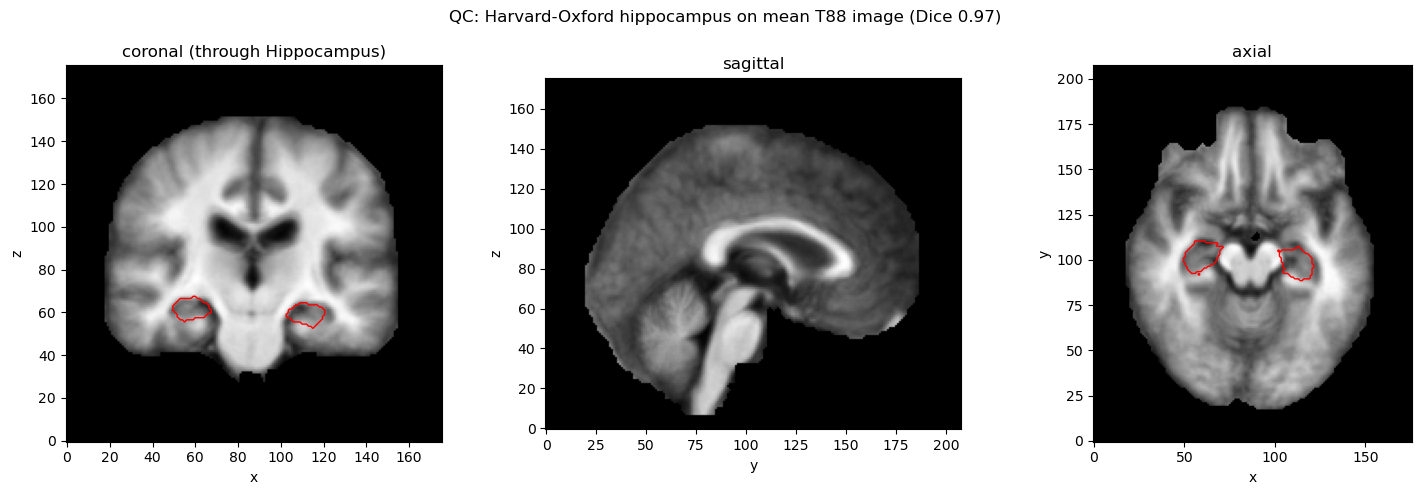

In [13]:
# ---------- ภาพตรวจคุณภาพ: ฮิปโปแคมปัสทับบนภาพเฉลี่ย (ดูด้วยตาว่าอยู่ตรงขมับในสมองหรือไม่) ----------
pts = np.argwhere(hip)
cen = pts.mean(0).round().astype(int)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
views = [(avg_img[:, cen[1], :].T, hip[:, cen[1], :].T, "coronal (through Hippocampus)", "x", "z"),
         (avg_img[cen[0], :, :].T, hip[cen[0], :, :].T, "sagittal", "y", "z"),
         (avg_img[:, :, cen[2]].T, hip[:, :, cen[2]].T, "axial", "x", "y")]
for a, (im, m, t, xl, yl) in zip(ax, views):
    a.imshow(im, cmap="gray", origin="lower")
    a.contour(m.astype(float), levels=[0.5], colors="r", linewidths=1)
    a.set_title(t); a.set_xlabel(xl); a.set_ylabel(yl)
plt.suptitle(f"QC: Harvard-Oxford hippocampus on mean T88 image (Dice {dice:.2f})")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "qc_overlay.png"), dpi=150); plt.show()


In [14]:
# ---------- นับว่าฮิปโปแคมปัสอยู่บนสไลซ์ที่โมเดลเห็นหรือไม่ (ตามขอบเขตการตัดของแต่ละคน) ----------
Tx, Ty, Tz = PL.TARGET_SHAPE
cx, cy, cz = PL.CENTER          # (64, 64, 48)
rows = []
for sid, (lo, hi) in bboxes.items():
    D = hi - lo + 1
    # ตำแหน่งของสไลซ์ใน voxel ของภาพ T88 เดิม (scipy.zoom จัดมุมให้ตรงกัน: in = out * (D-1)/(T-1))
    step = (D - 1) / (np.array(PL.TARGET_SHAPE) - 1)         # มม. ต่อ 1 วอกเซลของภาพที่ย่อแล้ว
    pos = lo + np.array([cx, cy, cz]) * step                  # ตำแหน่ง sag, cor, axi
    row = {"id": sid, "ขนาดหลังตัด": "x".join(map(str, D)), "มม./วอกเซล (x,y,z)": np.round(step, 2).tolist()}
    for k, name in enumerate(["sagittal 64", "coronal 64", "axial 48"]):
        dist = np.abs(pts[:, k] - pos[k])
        half = 0.5 * step[k]
        row[f"{name}: ใกล้สุด (มม.)"] = round(float(dist.min()), 1)
        row[f"{name}: % ฮิปโปที่อยู่บนสไลซ์"] = round(100 * float((dist <= half).mean()), 1)
        row[f"{name}: % ใน ±{TOLERANCE_MM} มม."] = round(100 * float((dist <= TOLERANCE_MM).mean()), 1)
    rows.append(row)
tab = pd.DataFrame(rows)
tab.to_csv(os.path.join(OUT_DIR, "hippocampus_slice_check.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(tab)

say("\n=== สรุปการนับ (เฉลี่ยข้ามคนตัวอย่าง) ===")
verdicts = {}
for name, who in [("axial 48", "2D และ 2.5D"), ("coronal 64", "2.5D"), ("sagittal 64", "2.5D")]:
    near = tab[f"{name}: ใกล้สุด (มม.)"]
    on = tab[f"{name}: % ฮิปโปที่อยู่บนสไลซ์"]
    tol = tab[f"{name}: % ใน ±{TOLERANCE_MM} มม."]
    if on.mean() > 0:
        v = "ผ่านฮิปโปแคมปัส"
    elif near.mean() <= TOLERANCE_MM:
        v = f"อยู่ใกล้มาก (ห่าง {near.mean():.1f} มม. อยู่ในช่วงความคลาดเคลื่อนของการจัดแนว) ยืนยันไม่ได้"
    else:
        v = f"ไม่ผ่านฮิปโปแคมปัส (ห่างที่สุดใกล้ {near.mean():.1f} มม.)"
    verdicts[name] = v
    say(f"สไลซ์ {name} (ใช้ใน {who}): ฮิปโปบนสไลซ์เฉลี่ย {on.mean():.1f}% | ใกล้สุดเฉลี่ย {near.mean():.1f} มม. "
        f"(ช่วง {near.min():.1f}-{near.max():.1f}) | อยู่ใน ±{TOLERANCE_MM} มม. {tol.mean():.1f}% -> {v}")
say("\nการตีความ: ถ้าสไลซ์ใดไม่ผ่านฮิปโปแคมปัส Grad-CAM ของโมเดลที่ใช้สไลซ์นั้นบอกอะไรเกี่ยวกับฮิปโปแคมปัสโดยตรงไม่ได้ "
    "(แต่ยังเห็นสัญญาณอื่นได้ เช่น โพรงน้ำในสมองขยาย) ผลนี้อิงตำแหน่ง atlas ค่าเฉลี่ย ไม่ใช่ฮิปโปแคมปัสของแต่ละคน")


,id,ขนาดหลังตัด,"มม./วอกเซล (x,y,z)",sagittal 64: ใกล้สุด (มม.),sagittal 64: % ฮิปโปที่อยู่บนสไลซ์,sagittal 64: % ใน ±5 มม.,coronal 64: ใกล้สุด (มม.),coronal 64: % ฮิปโปที่อยู่บนสไลซ์,coronal 64: % ใน ±5 มม.,axial 48: ใกล้สุด (มม.),axial 48: % ฮิปโปที่อยู่บนสไลซ์,axial 48: % ใน ±5 มม.
0,0001,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
1,0003,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
2,0010,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
3,0011,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
4,0016,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
5,0020,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
6,0022,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
7,0023,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
8,0030,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0
9,0032,137x171x145,"[1.07, 1.34, 1.52]",7.5,0.0,0.0,0.3,4.0,38.3,0.2,0.5,6.0



=== สรุปการนับ (เฉลี่ยข้ามคนตัวอย่าง) ===
สไลซ์ axial 48 (ใช้ใน 2D และ 2.5D): ฮิปโปบนสไลซ์เฉลี่ย 0.5% | ใกล้สุดเฉลี่ย 0.2 มม. (ช่วง 0.2-0.2) | อยู่ใน ±5 มม. 6.0% -> ผ่านฮิปโปแคมปัส
สไลซ์ coronal 64 (ใช้ใน 2.5D): ฮิปโปบนสไลซ์เฉลี่ย 4.0% | ใกล้สุดเฉลี่ย 0.3 มม. (ช่วง 0.3-0.3) | อยู่ใน ±5 มม. 38.3% -> ผ่านฮิปโปแคมปัส
สไลซ์ sagittal 64 (ใช้ใน 2.5D): ฮิปโปบนสไลซ์เฉลี่ย 0.0% | ใกล้สุดเฉลี่ย 7.5 มม. (ช่วง 7.5-7.5) | อยู่ใน ±5 มม. 0.0% -> ไม่ผ่านฮิปโปแคมปัส (ห่างที่สุดใกล้ 7.5 มม.)

การตีความ: ถ้าสไลซ์ใดไม่ผ่านฮิปโปแคมปัส Grad-CAM ของโมเดลที่ใช้สไลซ์นั้นบอกอะไรเกี่ยวกับฮิปโปแคมปัสโดยตรงไม่ได้ (แต่ยังเห็นสัญญาณอื่นได้ เช่น โพรงน้ำในสมองขยาย) ผลนี้อิงตำแหน่ง atlas ค่าเฉลี่ย ไม่ใช่ฮิปโปแคมปัสของแต่ละคน


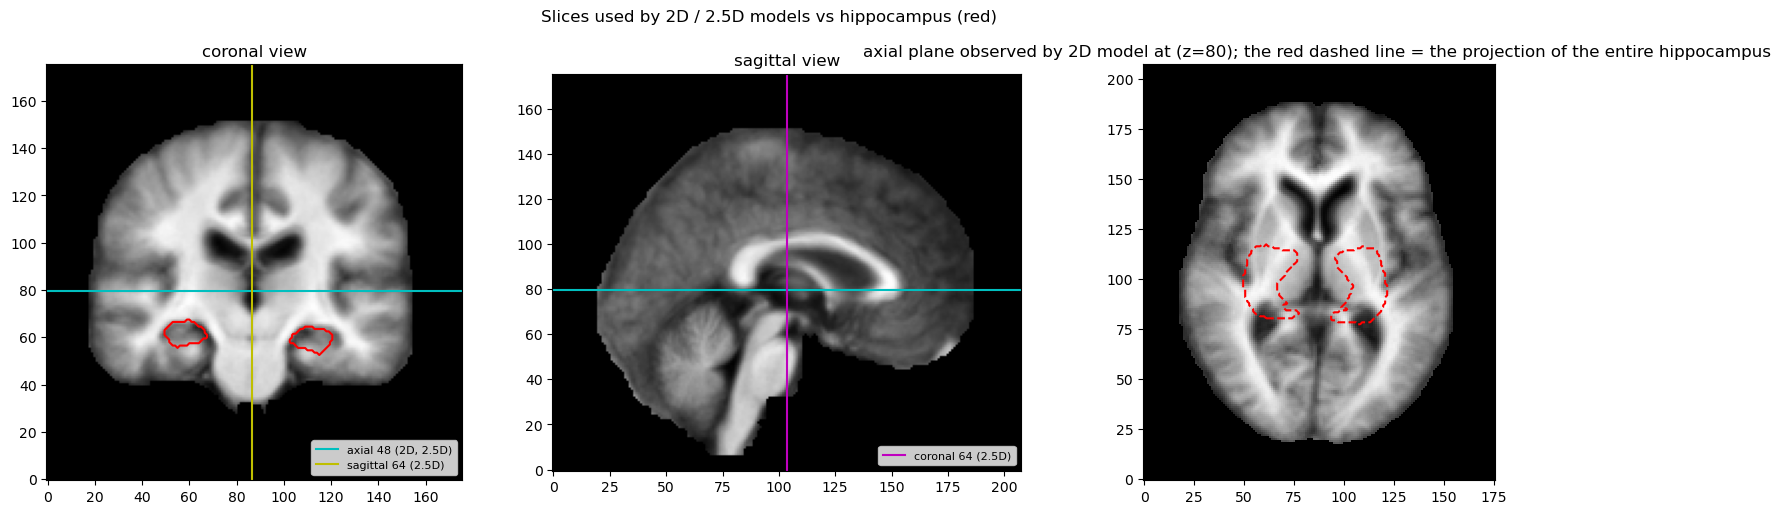

In [17]:
# ---------- ภาพ: ตำแหน่งสไลซ์ของโมเดลเทียบกับฮิปโปแคมปัส (ใช้ขอบเขตตัดเฉลี่ย) ----------
lo_m = np.mean([b[0] for b in bboxes.values()], axis=0)
D_m = np.mean([b[1] - b[0] + 1 for b in bboxes.values()], axis=0)
step_m = (D_m - 1) / (np.array(PL.TARGET_SHAPE) - 1)
pos_m = lo_m + np.array([cx, cy, cz]) * step_m          # (sag x, cor y, axi z) ในพิกัด T88
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
ax[0].imshow(avg_img[:, cen[1], :].T, cmap="gray", origin="lower"); ax[0].contour(hip[:, cen[1], :].T.astype(float), [0.5], colors="r")
ax[0].axhline(pos_m[2], color="c", label="axial 48 (2D, 2.5D)"); ax[0].axvline(pos_m[0], color="y", label="sagittal 64 (2.5D)")
ax[0].set_title("coronal view"); ax[0].legend(loc="lower right", fontsize=8)
ax[1].imshow(avg_img[cen[0], :, :].T, cmap="gray", origin="lower"); ax[1].contour(hip[cen[0], :, :].T.astype(float), [0.5], colors="r")
ax[1].axhline(pos_m[2], color="c"); ax[1].axvline(pos_m[1], color="m", label="coronal 64 (2.5D)")
ax[1].set_title("sagittal view"); ax[1].legend(loc="lower right", fontsize=8)
zi = int(round(pos_m[2]))
ax[2].imshow(avg_img[:, :, zi].T, cmap="gray", origin="lower")
ax[2].contour(hip.any(axis=2).T.astype(float), [0.5], colors="r", linestyles="--")
ax[2].set_title(f"axial plane observed by 2D model at (z={zi}); the red dashed line = the projection of the entire hippocampus ")
plt.suptitle("Slices used by 2D / 2.5D models vs hippocampus (red)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "slice_vs_hippocampus.png"), dpi=150); plt.show()


## เขียนรายงาน

In [18]:
with open(os.path.join(OUT_DIR, "A_report.txt"), "w") as f:
    f.write("\n".join(REPORT))
print("บันทึกแล้วที่", os.path.abspath(OUT_DIR))
for fn in sorted(os.listdir(OUT_DIR)):
    print("  ", fn)
print("\nส่งไฟล์ A_report.txt และภาพ qc_overlay.png, slice_vs_hippocampus.png มาให้ดู")


บันทึกแล้วที่ /home/jovyan/Alzheimer's/src/01-data-review/A_check_output
   A_report.txt
   avg_T88.npy
   hippocampus_T88.npy
   hippocampus_slice_check.csv
   qc_overlay.png
   slice_vs_hippocampus.png
   template_to_T88.tfm

ส่งไฟล์ A_report.txt และภาพ qc_overlay.png, slice_vs_hippocampus.png มาให้ดู
